# MSCS 634 — Deliverable 3: Classification, Clustering, and Association Rules

This notebook analyzes 569 Wisconsin Diagnostic Breast Cancer observations, with 30 measurements from digitized images and a recorded benign or malignant diagnosis. It compares classifiers, looks for groups without using the diagnosis labels, and tests which combinations of high measurements are associated with malignancy. [UCI dataset documentation](https://doi.org/10.24432/C5DW2B)

## 1. Define the task and holdout

The CSV codes malignant as 0 and benign as 1. Recode **malignant as the positive class** so precision, recall, F1, and average precision describe that outcome. Remove diagnosis from the predictors. A fixed stratified 80/20 split separates training from evaluation, and the five training folds also preserve the class mix.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display
from mlxtend.frequent_patterns import apriori, association_rules
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay, accuracy_score, adjusted_rand_score, average_precision_score,
    confusion_matrix, f1_score, precision_recall_curve, precision_score, recall_score,
    roc_auc_score, roc_curve, silhouette_score,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from threadpoolctl import threadpool_limits

sns.set_theme(style="whitegrid", palette="colorblind")
seed = 42
df = pd.read_csv("breast_cancer.csv")
X = df.drop(columns="target")
assert df["target"].isin([0, 1]).all()
y = df["target"].eq(0).astype(int)
print(f"{len(df)} observations, {X.shape[1]} measurements, "
      f"{int(df.isna().sum().sum())} missing values, {int(df.duplicated().sum())} duplicate rows")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=seed,
)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=seed)
diagnosis = {0: "Benign", 1: "Malignant"}
display(pd.DataFrame({
    "Training": y_train.map(diagnosis).value_counts(),
    "Holdout": y_test.map(diagnosis).value_counts(),
}))

569 observations, 30 measurements, 0 missing values, 0 duplicate rows


,Training,Holdout
target,,
Benign,285,72
Malignant,170,42


## 2. Train and tune the classifiers

**Logistic regression** models the log-odds of malignancy. Its pipeline standardizes inputs within each training fold, giving regularization a consistent scale across measurements. A **decision tree** can represent thresholds and interactions between measurements. Compare its unrestricted default version with a tuned version.

The search tests 48 combinations using five stratified training folds. Maximum depth from 2 through 6 and unlimited compares simple and flexible trees. Minimum leaf sizes from 1 to 10 discourage splits supported by very few observations. Balanced class weights test whether emphasizing the less frequent malignant class helps. Select the highest mean malignant F1, which balances precision and recall for malignant cases.

In [2]:
logistic = make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000))
default_tree = DecisionTreeClassifier(random_state=seed)
grid = {
    "max_depth": [2, 3, 4, 5, 6, None],
    "min_samples_leaf": [1, 2, 5, 10],
    "class_weight": [None, "balanced"],
}
search = GridSearchCV(DecisionTreeClassifier(random_state=seed), grid, cv=cv, scoring="f1")
search.fit(X_train, y_train)
models = {
    "Logistic regression": logistic.fit(X_train, y_train),
    "Default decision tree": default_tree.fit(X_train, y_train),
    "Tuned decision tree": search.best_estimator_,
}
cv_f1 = {
    "Logistic regression": cross_val_score(logistic, X_train, y_train, cv=cv, scoring="f1").mean(),
    "Default decision tree": cross_val_score(default_tree, X_train, y_train, cv=cv, scoring="f1").mean(),
    "Tuned decision tree": search.best_score_,
}
print(f"{len(search.cv_results_['params'])} configurations. Selected parameters: {search.best_params_}")
print(f"Default tree mean CV F1: {cv_f1['Default decision tree']:.3f}; "
      f"selected tree mean CV F1: {search.best_score_:.3f}")
tuning = pd.DataFrame(search.cv_results_).sort_values("rank_test_score")
display(tuning[[
    "rank_test_score", "param_max_depth", "param_min_samples_leaf", "param_class_weight",
    "mean_test_score", "std_test_score",
]].head(8).round(4))

48 configurations. Selected parameters: {'class_weight': 'balanced', 'max_depth': 5, 'min_samples_leaf': 5}
Default tree mean CV F1: 0.896; selected tree mean CV F1: 0.938


,rank_test_score,param_max_depth,param_min_samples_leaf,param_class_weight,mean_test_score,std_test_score
46,1,None,5,balanced,0.9378,0.0297
38,1,5,5,balanced,0.9378,0.0297
34,3,4,5,balanced,0.9350,0.0271
42,3,6,5,balanced,0.9350,0.0271
31,5,3,10,balanced,0.9255,0.0296
35,5,4,10,balanced,0.9255,0.0296
39,5,5,10,balanced,0.9255,0.0296
47,5,None,10,balanced,0.9255,0.0296


## 3. Evaluate classification on the holdout

Report accuracy, malignant precision and recall, benign specificity, malignant F1, ROC AUC, and average precision. Recall measures the share of malignant cases detected. Specificity measures the share of benign cases correctly classified. The confusion matrices show counts at each classifier's default threshold. The ROC and precision–recall curves compare a range of thresholds. The selected tree's training CV score was used during tuning, so the holdout is the independent comparison.

In [3]:
scores = []
holdout_scores = {}
for name, model in models.items():
    predicted = model.predict(X_test)
    probability = model.predict_proba(X_test)[:, list(model.classes_).index(1)]
    tn, fp, fn, tp = confusion_matrix(y_test, predicted, labels=[0, 1]).ravel()
    holdout_scores[name] = (predicted, probability)
    scores.append({
        "Model": name, "Training CV F1": cv_f1[name],
        "Accuracy": accuracy_score(y_test, predicted),
        "Malignant precision": precision_score(y_test, predicted),
        "Malignant recall": recall_score(y_test, predicted),
        "Benign specificity": tn / (tn + fp),
        "Malignant F1": f1_score(y_test, predicted),
        "ROC AUC": roc_auc_score(y_test, probability),
        "Average precision": average_precision_score(y_test, probability),
        "False negatives": fn, "False positives": fp,
    })

classification_results = pd.DataFrame(scores)
display(classification_results.round(4))
classification_results.to_csv("classification_results.csv", index=False)
print(f"Always predicting benign gives {y_test.eq(0).mean():.1%} accuracy "
      "and zero malignant recall on this holdout.")

,Model,Training CV F1,Accuracy,Malignant precision,Malignant recall,Benign specificity,Malignant F1,ROC AUC,Average precision,False negatives,False positives
0,Logistic regression,0.9640,0.9649,0.9750,0.9286,0.9861,0.9512,0.9960,0.9943,3,1
1,Default decision tree,0.8962,0.9298,0.9048,0.9048,0.9444,0.9048,0.9246,0.8537,4,4
2,Tuned decision tree,0.9378,0.9035,0.8974,0.8333,0.9444,0.8642,0.9076,0.9120,7,4


Always predicting benign gives 63.2% accuracy and zero malignant recall on this holdout.


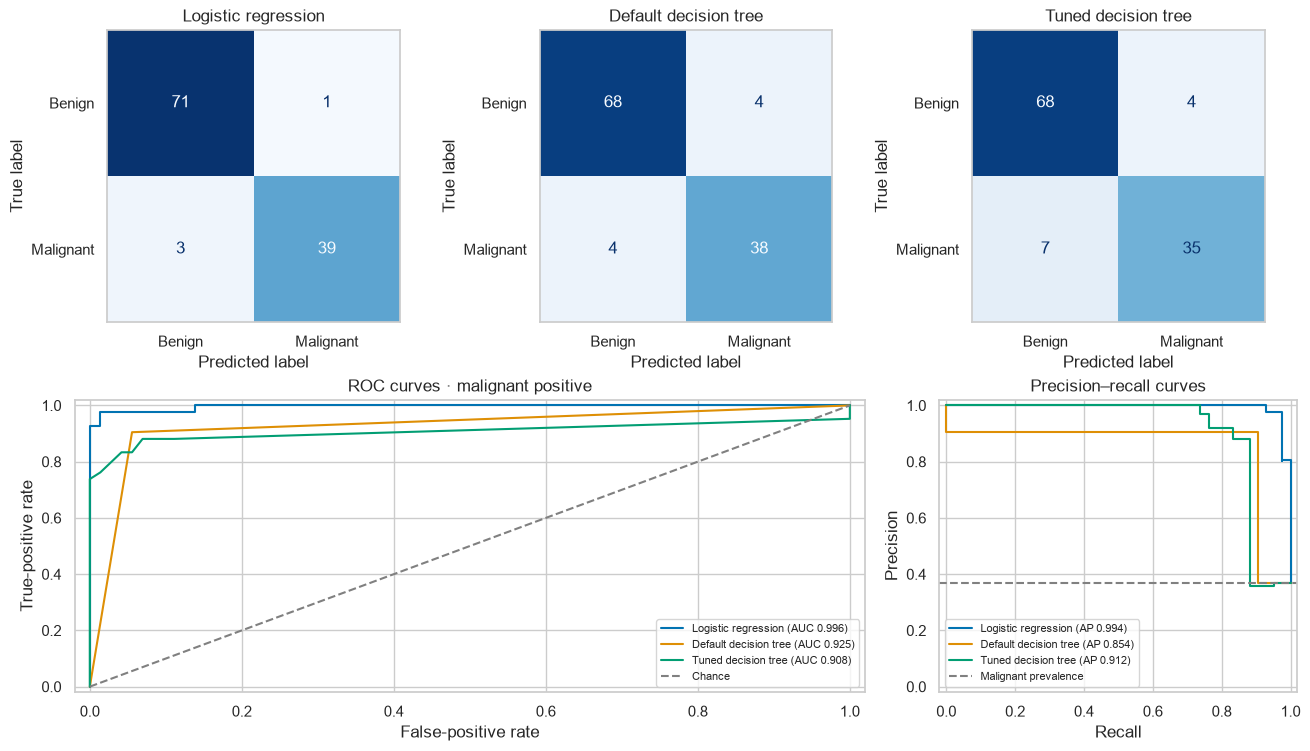

In [4]:
fig, axes = plt.subplot_mosaic(
    [["logistic", "default", "tuned"], ["roc", "roc", "pr"]],
    figsize=(13, 7.4), layout="constrained",
)
shades = sns.color_palette("colorblind", len(models))
for name, panel, shade in zip(models, ("logistic", "default", "tuned"), shades):
    predicted, probability = holdout_scores[name]
    ConfusionMatrixDisplay.from_predictions(
        y_test, predicted, labels=[0, 1], display_labels=["Benign", "Malignant"],
        cmap="Blues", colorbar=False, im_kw={"vmin": 0, "vmax": y_test.value_counts().max()},
        ax=axes[panel],
    )
    axes[panel].set_title(name)
    axes[panel].grid(False)
    fpr, tpr, _ = roc_curve(y_test, probability)
    precision, recall, _ = precision_recall_curve(y_test, probability)
    axes["roc"].plot(fpr, tpr, color=shade, label=f"{name} (AUC {roc_auc_score(y_test, probability):.3f})")
    axes["pr"].step(recall, precision, where="post", color=shade,
                    label=f"{name} (AP {average_precision_score(y_test, probability):.3f})")

axes["roc"].plot([0, 1], [0, 1], "--", color="gray", label="Chance")
axes["roc"].set(title="ROC curves · malignant positive", xlabel="False-positive rate",
                ylabel="True-positive rate", xlim=(-0.02, 1.02), ylim=(-0.02, 1.02))
axes["roc"].legend(loc="lower right", fontsize=8)
axes["pr"].axhline(y_test.mean(), linestyle="--", color="gray", label="Malignant prevalence")
axes["pr"].set(title="Precision–recall curves", xlabel="Recall", ylabel="Precision",
               xlim=(-0.02, 1.02), ylim=(-0.02, 1.02))
axes["pr"].legend(loc="lower left", fontsize=8)
fig.savefig("classification_performance.png", dpi=160, bbox_inches="tight")
plt.show()

## 4. Identify clusters in the measurements

K-means assigns observations by distance from centroids. Standardization gives measurements on different scales comparable weight. Compare cluster counts 2–8 using 20 initializations per count. Select the count with the highest training silhouette, which summarizes cohesion and separation. Inertia shows how within-cluster distances shrink as more centroids are added.

Fit the scaler, K-means, and PCA on training data. K-means and silhouette scoring use all 30 standardized measurements. PCA reduces those measurements to two components for display. Use diagnosis only after clustering to summarize agreement on the holdout through the adjusted Rand index and a cross-tabulation. Cluster numbers are arbitrary.

In [5]:
scaler = StandardScaler().fit(X_train)
z_train = scaler.transform(X_train)
z_test = scaler.transform(X_test)
cluster_models = {}
evaluations = []
with threadpool_limits(limits=2):
    for k in range(2, 9):
        clusterer = KMeans(n_clusters=k, n_init=20, random_state=seed).fit(z_train)
        cluster_models[k] = clusterer
        evaluations.append({
            "Clusters": k, "Training silhouette": silhouette_score(z_train, clusterer.labels_),
            "Training inertia": clusterer.inertia_,
        })

cluster_results = pd.DataFrame(evaluations)
best_k = int(cluster_results.loc[cluster_results["Training silhouette"].idxmax(), "Clusters"])
cluster_results["Selected"] = cluster_results["Clusters"].eq(best_k)
cluster_results.to_csv("clustering_results.csv", index=False)
display(cluster_results.round(4))
clusterer = cluster_models[best_k]
test_clusters = pd.Series(clusterer.predict(z_test), index=X_test.index, name="Cluster")
holdout_silhouette = silhouette_score(z_test, test_clusters)
holdout_ari = adjusted_rand_score(y_test, test_clusters)
cluster_counts = pd.crosstab(test_clusters, y_test.map(diagnosis).rename("Diagnosis"))
cluster_profiles = X_test.assign(Cluster=test_clusters).groupby("Cluster")[
    ["mean radius", "mean concavity", "worst perimeter"]
].median()
print(f"Selected k = {best_k} | Holdout silhouette = {holdout_silhouette:.3f} | "
      f"Holdout adjusted Rand index = {holdout_ari:.3f}")
display(cluster_counts)
display(cluster_profiles.round(3))

,Clusters,Training silhouette,Training inertia,Selected
0,2,0.3432,9254.8273,True
1,3,0.3233,8075.3173,False
2,4,0.2782,7344.3357,False
3,5,0.1612,6808.3865,False
4,6,0.1617,6328.6479,False
5,7,0.1496,5991.5497,False
6,8,0.1542,5639.0917,False


Selected k = 2 | Holdout silhouette = 0.317 | Holdout adjusted Rand index = 0.617


Diagnosis,Benign,Malignant
Cluster,,
0,69,9
1,3,33


,mean radius,mean concavity,worst perimeter
Cluster,,,
0,12.585,0.041,88.62
1,18.210,0.169,140.55


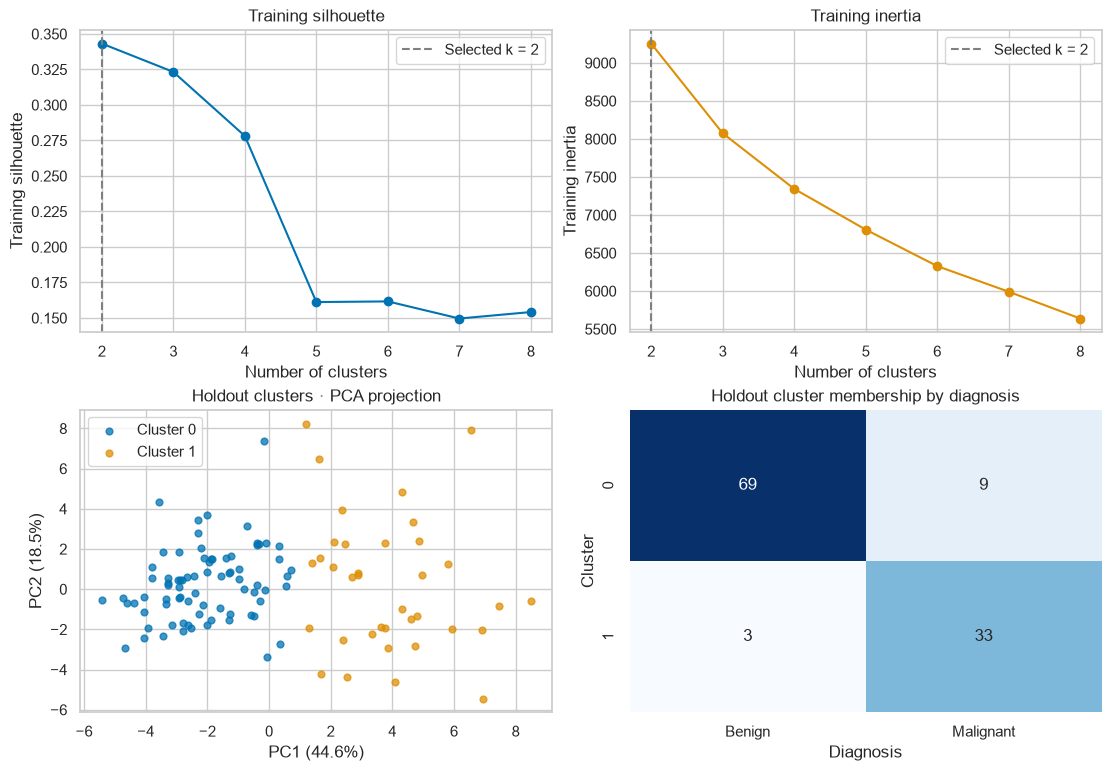

In [6]:
pca = PCA(n_components=2).fit(z_train)
projection = pca.transform(z_test)
explained = pca.explained_variance_ratio_

fig, axes = plt.subplots(2, 2, figsize=(11, 7.6), layout="constrained")
for ax, column, color in [
    (axes[0, 0], "Training silhouette", shades[0]),
    (axes[0, 1], "Training inertia", shades[1]),
]:
    ax.plot(cluster_results["Clusters"], cluster_results[column], "o-", color=color)
    ax.axvline(best_k, color="gray", linestyle="--", label=f"Selected k = {best_k}")
    ax.set(title=column, xlabel="Number of clusters", ylabel=column, xticks=cluster_results["Clusters"])
    ax.legend()

for cluster_id in sorted(test_clusters.unique()):
    mask = test_clusters.eq(cluster_id).to_numpy()
    axes[1, 0].scatter(*projection[mask].T, s=24, alpha=0.75, label=f"Cluster {cluster_id}")
axes[1, 0].set(
    title="Holdout clusters · PCA projection", xlabel=f"PC1 ({explained[0]:.1%})",
    ylabel=f"PC2 ({explained[1]:.1%})",
)
axes[1, 0].legend()
sns.heatmap(cluster_counts, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[1, 1])
axes[1, 1].set_title("Holdout cluster membership by diagnosis")
fig.savefig("clustering_summary.png", dpi=160, bbox_inches="tight")
plt.show()

## 5. Mine and validate association rules

Use five prespecified measurements spanning size, texture, and shape. Mark a measurement high at or above its training median. Add a malignant outcome item. Apriori finds frequent itemsets of up to three items, so a rule may combine up to two measurements with the malignant outcome. Require training support of at least 12%, confidence of at least 60%, and lift of at least 1.20. The support threshold requires at least 55 training observations with the full pattern.

- **Support** is the share of all observations containing both sides of the rule.
- **Confidence** is the share containing the outcome among observations matching the antecedent.
- **Lift** divides confidence by the outcome's prevalence. Values above 1 indicate positive association.

Rank rules by training lift, then support. Validate each qualifying rule on the holdout with the original thresholds. The table and chart show the top five rules plus the highest-ranked single-measurement rule. Their selection uses training results.

In [7]:
rule_features = ["mean radius", "mean texture", "mean concavity", "mean compactness", "mean smoothness"]
thresholds = X_train[rule_features].median()
flags_train = X_train[rule_features].ge(thresholds).add_prefix("High ")
flags_test = X_test[rule_features].ge(thresholds).add_prefix("High ")
flags_train["Malignant"] = y_train.eq(1)
flags_test["Malignant"] = y_test.eq(1)
display(thresholds.rename("Training median").to_frame().round(4))

frequent = apriori(flags_train, min_support=0.12, use_colnames=True, max_len=3)
discovered = association_rules(
    frequent, num_itemsets=len(flags_train), metric="confidence", min_threshold=0.60,
)
candidates = discovered.loc[
    discovered["consequents"].eq(frozenset({"Malignant"})) & discovered["lift"].ge(1.20)
].copy()
candidates["Rule"] = candidates["antecedents"].map(lambda items: " + ".join(sorted(items)))
candidates = candidates.sort_values(["lift", "support", "Rule"], ascending=[False, False, True])

rule_records = []
for rule in candidates.to_dict("records"):
    matches = flags_test[sorted(rule["antecedents"])].all(axis=1)
    joint = matches & flags_test["Malignant"]
    matching_count = int(matches.sum())
    confidence = int(joint.sum()) / matching_count if matching_count else np.nan
    rule_records.append({
        "Rule toward malignancy": rule["Rule"], "Antecedent size": len(rule["antecedents"]),
        "Training support": rule["support"], "Training confidence": rule["confidence"],
        "Training lift": rule["lift"], "Holdout matches": matching_count,
        "Holdout malignant matches": int(joint.sum()), "Holdout support": joint.mean(),
        "Holdout confidence": confidence, "Holdout lift": confidence / flags_test["Malignant"].mean(),
    })

rules = pd.DataFrame(rule_records)
rules.to_csv("association_rules.csv", index=False)
shown = pd.concat([rules.head(5), rules.loc[rules["Antecedent size"].eq(1)].head(1)]).drop_duplicates()
print(f"{len(rules)} rules met the training thresholds. Holdout malignant prevalence: "
      f"{flags_test['Malignant'].mean():.1%}")
display(shown.round(4))

,Training median
mean radius,13.3400
mean texture,18.9000
mean concavity,0.0594
mean compactness,0.0923
mean smoothness,0.0952


13 rules met the training thresholds. Holdout malignant prevalence: 36.8%


,Rule toward malignancy,Antecedent size,Training support,Training confidence,Training lift,Holdout matches,Holdout malignant matches,Holdout support,Holdout confidence,Holdout lift
0,High mean concavity + High mean radius,2,0.3143,0.8512,2.2782,46,40,0.3509,0.8696,2.3602
1,High mean radius + High mean texture,2,0.2703,0.8425,2.2548,36,32,0.2807,0.8889,2.4127
2,High mean compactness + High mean radius,2,0.2901,0.8354,2.2360,40,34,0.2982,0.8500,2.3071
3,High mean radius + High mean smoothness,2,0.2330,0.8346,2.2339,33,25,0.2193,0.7576,2.0563
4,High mean concavity + High mean texture,2,0.2615,0.8041,2.1520,41,33,0.2895,0.8049,2.1847
10,High mean concavity,1,0.3429,0.6842,1.8313,62,42,0.3684,0.6774,1.8387


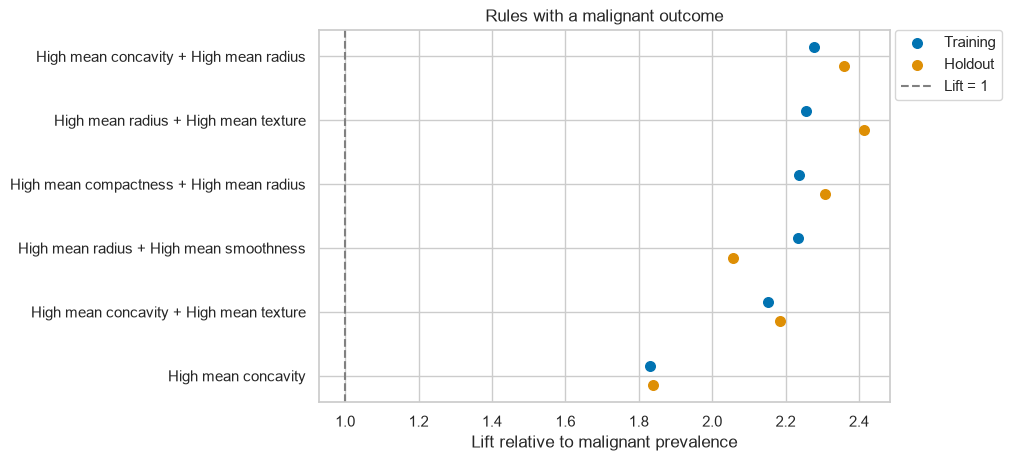

In [8]:
fig, ax = plt.subplots(figsize=(10, 4.5), layout="constrained")
positions = np.arange(len(shown))
for offset, column, label, color in [
    (-0.15, "Training lift", "Training", shades[0]), (0.15, "Holdout lift", "Holdout", shades[1]),
]:
    ax.scatter(shown[column], positions + offset, color=color, s=48, label=label)
ax.axvline(1, color="gray", linestyle="--", label="Lift = 1")
ax.set(title="Rules with a malignant outcome", xlabel="Lift relative to malignant prevalence",
       yticks=positions, yticklabels=shown["Rule toward malignancy"])
ax.invert_yaxis()
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), borderaxespad=0)
fig.savefig("association_rule_lift.png", dpi=160, bbox_inches="tight")
plt.show()

## 6. Interpret the results

- **Classification.** Logistic regression recorded the highest holdout accuracy (96.49%) and malignant F1 (0.951), with 39 of 42 malignant cases detected. Tuning raised mean training CV F1 from 0.896 to 0.938 and increased holdout average precision from 0.854 to 0.912. At the default decision threshold, the tuned tree missed seven malignant cases versus four for the unrestricted tree, and holdout F1 fell from 0.905 to 0.864. This run favors logistic regression overall.
- **Clustering.** Two clusters gave the highest training silhouette (0.343), with a holdout silhouette of 0.317. The higher-radius group had median radius 18.210 and contained 33 malignant and 3 benign observations. The other group had median radius 12.585 and contained 9 malignant and 69 benign observations. The adjusted Rand index was 0.617. The PCA plot and mixed diagnosis counts show that the groups overlap.
- **Association.** High mean concavity plus high mean radius was the top rule by training lift. On the holdout it had 35.09% support and 86.96% confidence (40 malignant cases among 46 matches), giving 2.36 lift relative to the 36.84% malignant prevalence. High concavity alone covered more cases (62 matches) and had 67.74% confidence. The rule can guide a dataset audit or motivate testing a feature interaction in a future model. Correlated contour measurements and the median cutoffs influence which rules appear.

These results describe a historical benchmark from one source and one holdout. The data lack demographic fields for assessing subgroup performance. Independent imaging data would help assess how well the patterns transfer.